# 05. Оцінювання попередньо обраної моделі

Для навчального експерименту до перегляду цих результатів зафіксовано Logistic Regression (`C=1`, `class_weight=balanced`): вона отримала найбільший середній F1 у попередньому пошуку на навчальній частині. Поріг 0,5 не оптимізувався. Це не бізнес-оптимальний вибір; мета й вартість помилок ще не визначені. Тестова вибірка вже частково потрапляла до первинного EDA, тож результат не є повністю незалежним.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_split import load_dataset, split_dataset
from src.preprocessing import prepare_xy
from src.evaluate import THRESHOLD, build_selected_model, evaluate_predictions

path = project_root / 'data' / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
train, test = split_dataset(load_dataset(path))
X_train, y_train = prepare_xy(train)
X_test, y_test = prepare_xy(test)
model = build_selected_model()
model.fit(X_train, y_train)
scores = model.predict_proba(X_test)[:, 1]
metrics, matrix = evaluate_predictions(y_test, scores)
print(f'Навчальних записів: {len(X_train)}; тестових: {len(X_test)}; поріг: {THRESHOLD}')

Навчальних записів: 5634; тестових: 1409; поріг: 0.5


## Результати на відкладеній вибірці

`average_precision` — підсумок precision-recall кривої, а не трапецієподібна площа PR-кривої. Через ваги класів вихідні scores не обов'язково є каліброваними ймовірностями. ROC-AUC та average precision обчислюються за scores, інші метрики — при фіксованому порозі 0,5.

,test
precision,0.5115
recall,0.8316
f1,0.6334
roc_auc,0.8537
average_precision,0.6700


Матриця помилок: рядки — фактичний клас, стовпці — прогноз; порядок No, Yes


,Predicted No,Predicted Yes
Actual No,738,297
Actual Yes,63,311


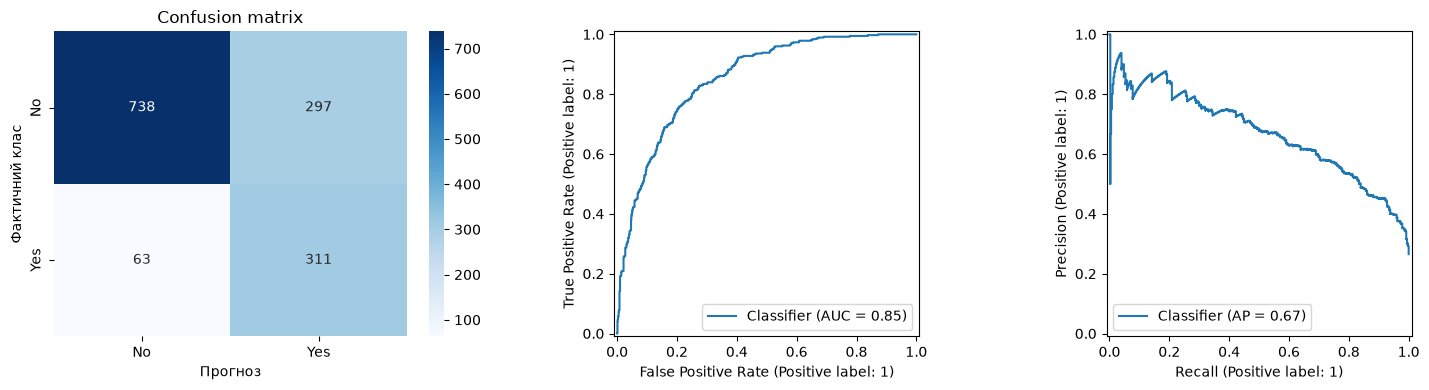

In [2]:
display(pd.Series(metrics, name='test').round(4).to_frame())
print('Матриця помилок: рядки — фактичний клас, стовпці — прогноз; порядок No, Yes')
display(pd.DataFrame(matrix, index=['Actual No', 'Actual Yes'], columns=['Predicted No', 'Predicted Yes']))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
axes[0].set(title='Confusion matrix', xlabel='Прогноз', ylabel='Фактичний клас')
RocCurveDisplay.from_predictions(y_test, scores, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, scores, ax=axes[2])
fig.tight_layout()
plt.show()

## Аналіз помилок

FP — клієнт залишився, але модель прогнозує відтік; FN — модель не виявила клієнта, який пішов. Порівняння за контрактом є описовим і не доводить причин. Не використовуйте ці результати для повторного підбору моделі чи порога на тому самому тесті.

In [3]:
predicted = (scores >= THRESHOLD).astype(int)
analysis = pd.DataFrame({'contract': X_test['Contract'].to_numpy(), 'actual': y_test.to_numpy(), 'predicted': predicted})
analysis['false_positive'] = (analysis['actual'] == 0) & (analysis['predicted'] == 1)
analysis['false_negative'] = (analysis['actual'] == 1) & (analysis['predicted'] == 0)
summary = analysis.groupby('contract', dropna=False).agg(
    customers=('actual', 'size'), actual_no=('actual', lambda x: (x == 0).sum()),
    actual_yes=('actual', 'sum'), false_positives=('false_positive', 'sum'),
    false_negatives=('false_negative', 'sum')
)
summary['false_positive_rate'] = summary['false_positives'] / summary['actual_no'].replace(0, float('nan'))
summary['false_negative_rate'] = summary['false_negatives'] / summary['actual_yes'].replace(0, float('nan'))
display(summary.round(4))

,customers,actual_no,actual_yes,false_positives,false_negatives,false_positive_rate,false_negative_rate
contract,,,,,,,
Month-to-month,789,457,332,281,27,0.6149,0.0813
One year,281,247,34,16,28,0.0648,0.8235
Two year,339,331,8,0,8,0.0000,1.0000


## Що далі

Порівняння всіх моделей наведено в `04_model_training.ipynb`; це порівняння використовує ті самі фолди для налаштування, тому може бути оптимістичним. Для практичного вибору визначте вартість помилок і використайте нові дані або вкладену крос-валідацію; фінально перевірте вибір на окремих зовнішніх або майбутніх даних.